# Datascape 2026 · Package condition (Aman / Rusak / Lainnya) · Final reproducible pipeline

**Metric** macro-F1 · **LB** 30% public / 70% private · **Team best public LB** 0.87739 (`d05_p416_allA`)

## What this notebook does
It builds the team's submissions end to end. Each stage records the evidence that decided it.

| § | Stage | Key result |
|---|---|---|
| 0 | Setup and preflight | every input is checked before any GPU time is spent |
| 1 | EDA | the image size identifies 6 data sources; per-source class rates differ wildly between train and test |
| 2 | Data cleaning | pixel-exact copies (dihedral NCC) and SSCD near-copies; train↔train label agreement 96%; cleanlab audit |
| 3 | Data processing | median-3 denoise, native-size resize, geometric views; DINOv2-cluster group folds |
| 4 | Augmentation | the fine-tune augmentations; the "always corrupt" variant was tested and closed |
| 5 | Model I | 11 frozen vision towers + MLP heads (h2), group-OOF |
| 6 | Pseudo-labels | twin lock (SSCD ≥ 0.55, purity ≥ 0.9) + domain-adapted heads |
| 7 | Post-processing | no-twin Rusak bias, mixed-vote calibration, per-stratum matching → `d04_da_bt2` (LB 0.84521) |
| 8 | LB-anchored source rules | 416/675 test rows are Aman → `d05_p416_allA` (LB 0.87739), `d06_cur_A` |
| 9 | Model II (re-modelling) | DINOv3-H+ full fine-tune breaks half of the augmentation shortcut; final model F1 = full-fit + pseudo-labels |
| 10 | Ensemble, TTA, candidates | F1 disagreements on 640/other rows with no copy |
| 11 | Error analysis | LB history, paired probe reads, joint LB inversion, confusion by source |
| 12 | Autoresearch ratchet + iteration log | paired LB probes (KEEP/DISCARD) and every experiment ranked by evidence |
| 13 | Final submissions | 2 picks with expected scores and reasons |

## How to run
- **Colab A100 (recommended).**
  - Put a Kaggle token in the Colab Secret `KAGGLE_API_TOKEN`.
  - Run `colab/run_final.py`. It downloads the images and cached artifacts, mounts Drive and executes this notebook. The executed notebook and the submissions are saved to Drive `datascape_2026/final`.
- **Modes** (environment variables):
  - `DS_FULL=1` turns everything on.
  - Single stages can be switched on individually: `DS_RECOMPUTE_EMB`, `DS_RECOMPUTE_PIX`, `DS_RETRAIN_HEADS`, `DS_RETRAIN_FT`.
  - The default QUICK mode needs no GPU and runs in minutes.
- **Determinism.** QUICK mode reproduces the submitted files exactly and asserts it. Re-trained models differ slightly across GPUs and seeds, so FULL mode reports its agreement with the cached predictions instead of asserting it.

**Rules compliance and AI declaration.**
- Only organiser data is used.
- No LLM/VLM inference is used. CLIP/SigLIP/PE/EVA/DINO towers are used as image encoders only: no text, no zero-shot.
- No labels were set by hand. Every decision is an algorithmic rule applied to whole groups of rows.
- Code was written with an AI coding assistant (Claude, Anthropic).

In [1]:
import os, sys, json, time, glob, hashlib, shutil, subprocess, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from sklearn.metrics import f1_score, confusion_matrix
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
LOCAL = os.environ.get('DS_LOCAL') == '1'; COLAB = os.path.isdir('/content') and not LOCAL
ROOT = Path(os.environ.get('DS_ROOT') or ('/content/ds' if COLAB else (Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()))).resolve()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / 'work'))
IMG = Path(os.environ.get('DS_IMG') or ('/content/in/small512/small' if COLAB else ROOT / 'work/small'))      # 512-px image cache (work/resize_cache.py)
DRIVE = Path(os.environ.get('DS_DRIVE') or ('/content/drive/MyDrive/datascape_2026' if COLAB else ROOT / 'work/drive_local'))
OUT = Path(os.environ.get('DS_OUTF') or ('/content/out_final' if COLAB else ROOT / 'notebook/output')); OUT.mkdir(parents=True, exist_ok=True)
FULL = os.environ.get('DS_FULL') == '1'
flag = lambda k: FULL or os.environ.get(f'DS_{k}') == '1'
RECOMPUTE_EMB, RECOMPUTE_PIX, RETRAIN_HEADS, RETRAIN_FT = flag('RECOMPUTE_EMB'), flag('RECOMPUTE_PIX'), flag('RETRAIN_HEADS'), flag('RETRAIN_FT')
SEARCH = [Path('/content/code'), ROOT / 'work', ROOT / 'submissions', ROOT / 'datascape', ROOT, Path('/content/in/artifacts'),   # Colab: the pack (/content/code) overrides older snapshot copies
          DRIVE / 'session12', DRIVE / 'session11', DRIVE / 'session10', ROOT / 'work/drive_in/session12', ROOT / 'work/drive_in/session11', ROOT / 'work/drive_in/session10']
def find(rel, required=True):  # exact relative path under each root first; else the shallowest file with that basename (older duplicates live deeper)
    for r in SEARCH:
        if (r / rel).is_file(): return r / rel
    for r in SEARCH:
        h = sorted(glob.glob(f'{r}/**/{Path(rel).name}', recursive=True), key=lambda x: (x.count('/'), x)) if r.exists() else []
        if h: return Path(h[0])
    if required: raise FileNotFoundError(f'{rel} not found under {[str(r) for r in SEARCH if r.exists()]}')
C = np.array(['Aman', 'Lainnya', 'Rusak']); T0 = time.time()
PLAN = dict(preflight=1, eda=1, cleaning=2, processing=1, augmentation=1, model1=1, pseudo=1, postproc=1, rules=1, model2=1, candidates=1, errors=2, log=1, final=1)
if RECOMPUTE_EMB: PLAN['processing'] = 30
if RETRAIN_FT: PLAN['model2'] = 125
def stage(name):  # progress file for the runner's live status + ETA
    ks = list(PLAN); i = ks.index(name); after = sum(PLAN[k] for k in ks[i + 1:])
    json.dump(dict(stage=name, ts=time.time(), cur_plan=PLAN[name], plan_after=after), open(OUT / 'progress.json', 'w'))
    print(f'== §{i} {name} | elapsed {(time.time() - T0) / 60:.1f} min | planned remaining {PLAN[name] + after} min', flush=True)
rel = lambda p: str(Path(p).relative_to(ROOT)) if ROOT in Path(p).parents else str(p)   # print paths relative to the repo root
def show(df, n=60): print(df.head(n).to_string() if isinstance(df, pd.DataFrame) else df)   # plain text renders everywhere (Drive viewer, GitHub, Kaggle)
print('env', 'Colab' if COLAB else 'local', '| root', ROOT.name, '| mode', 'FULL' if FULL else 'QUICK', dict(RECOMPUTE_EMB=RECOMPUTE_EMB, RECOMPUTE_PIX=RECOMPUTE_PIX, RETRAIN_HEADS=RETRAIN_HEADS, RETRAIN_FT=RETRAIN_FT))

env local | root datascape-2026-repo | mode QUICK {'RECOMPUTE_EMB': False, 'RECOMPUTE_PIX': False, 'RETRAIN_HEADS': False, 'RETRAIN_FT': False}


## Executive summary
| | |
|---|---|
| **Best public LB** | **0.87739** (`d05_p416_allA`); `d06_cur_A` and `d06_F1_AR25` are scored 10-06 |
| **What moved the score** | Twin lock + domain-adapted heads (+0.015); per-source rules read from paired LB probes (+0.032) |
| **Main error** | an *augmentation shortcut*: train Aman images are organiser-augmented and train Rusak images are raw, while every test image is raw → models over-call Rusak |
| **Re-modelling** | a full DINOv3-H+ fine-tune halves the shortcut (Rusak on LB-confirmed Aman rows 0.938 → 0.487) without losing true Rusak (0.978) |
| **Method** | autoresearch ratchet: one pre-registered hypothesis per paired LB probe, KEEP/DISCARD, base moves only on KEEP (§12) |

The diagram below is the pipeline that produces the submissions. Each box is one section of this notebook.

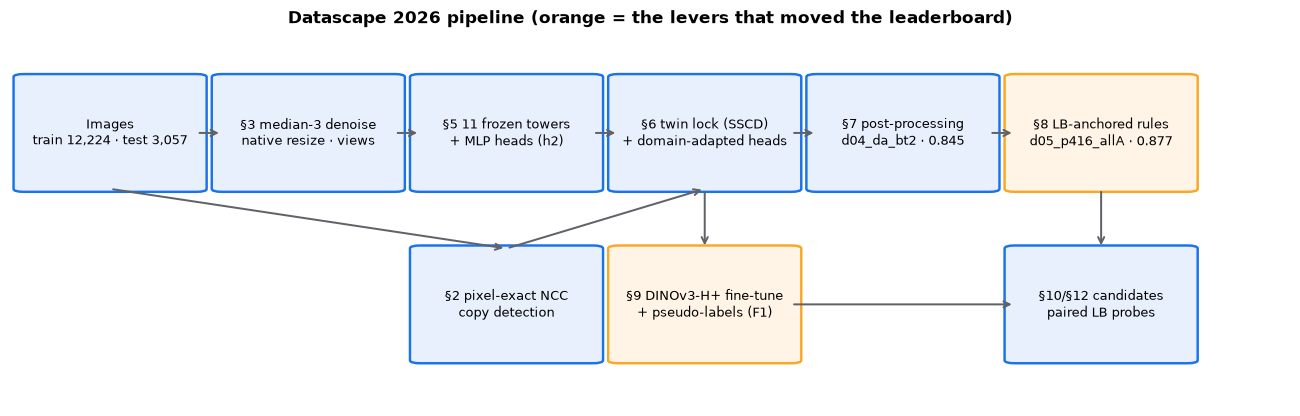

In [2]:
import matplotlib as mpl
from matplotlib.patches import FancyBboxPatch
mpl.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25,
                     'font.size': 10, 'axes.titleweight': 'bold', 'axes.titlesize': 11})
COL = {'Aman': '#2e7d32', 'Rusak': '#c62828', 'Lainnya': '#757575', 'blue': '#1a73e8', 'amber': '#f9a825'}
def annotate(ax, fmt='{:.2f}', horizontal=False):
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if v and np.isfinite(v):
            xy = (v, p.get_y() + p.get_height() / 2) if horizontal else (p.get_x() + p.get_width() / 2, v)
            ax.annotate(fmt.format(v), xy, ha='left' if horizontal else 'center', va='center' if horizontal else 'bottom', fontsize=8, xytext=(2, 0) if horizontal else (0, 1), textcoords='offset points')
fig, ax = plt.subplots(figsize=(15, 4.4)); ax.axis('off'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
B = {'img': (0.01, 0.58, 'Images\ntrain 12,224 · test 3,057'), 'pre': (0.165, 0.58, '§3 median-3 denoise\nnative resize · views'), 'tow': (0.32, 0.58, '§5 11 frozen towers\n+ MLP heads (h2)'),
     'da': (0.475, 0.58, '§6 twin lock (SSCD)\n+ domain-adapted heads'), 'pp': (0.63, 0.58, '§7 post-processing\nd04_da_bt2 · 0.845'), 'rule': (0.785, 0.58, '§8 LB-anchored rules\nd05_p416_allA · 0.877'),
     'ncc': (0.32, 0.12, '§2 pixel-exact NCC\ncopy detection'), 'ft': (0.475, 0.12, '§9 DINOv3-H+ fine-tune\n+ pseudo-labels (F1)'), 'cand': (0.785, 0.12, '§10/§12 candidates\npaired LB probes')}
for k, (x, y, t) in B.items():
    hi = k in ('rule', 'ft'); ax.add_patch(FancyBboxPatch((x, y), 0.135, 0.3, boxstyle='round,pad=0.008', fc='#fff4e5' if hi else '#e8f0fe', ec=COL['amber'] if hi else COL['blue'], lw=1.6))
    ax.text(x + 0.0675, y + 0.15, t, ha='center', va='center', fontsize=8.6)
for a, b in [('img', 'pre'), ('pre', 'tow'), ('tow', 'da'), ('da', 'pp'), ('pp', 'rule'), ('ncc', 'da'), ('ft', 'cand'), ('rule', 'cand'), ('img', 'ncc'), ('da', 'ft')]:
    (x0, y0, _), (x1, y1, _) = B[a], B[b]; s0 = (x0 + 0.135, y0 + 0.15) if abs(y0 - y1) < 0.01 else (x0 + 0.0675, y0 + (0 if y1 < y0 else 0.3))
    e0 = (x1, y1 + 0.15) if abs(y0 - y1) < 0.01 else (x1 + 0.0675, y1 + (0.3 if y1 < y0 else 0))
    ax.annotate('', e0, s0, arrowprops=dict(arrowstyle='->', color='#5f6368', lw=1.3))
ax.set_title('Datascape 2026 pipeline (orange = the levers that moved the leaderboard)'); plt.show()

## 0. Preflight
Every input is checked before any heavy stage runs, so a missing file fails here in seconds instead of after an hour of GPU time.

In [3]:
stage('preflight')
need = ['emb/meta_sorted.csv', 'meta_noise.csv', 'folds_group90.csv', 'nntr_sscd.npz', 'sample_submission.csv', 'ledger.csv', 'experiments.csv',
        'd04_da_bt2.csv', 'd05_p416_allA.csv', 'd05_p675_R.csv', 'd06_cur_A.csv', 'lbdelta.py', 'results.tsv'] + [f'preds/h2_peg_c11/pred_h2_peg_c11_f{k}.npz' for k in range(5)]
if not RETRAIN_HEADS: need += [f'preds/da_h2/pred_da_h2_f{k}.npz' for k in range(5)]
if RETRAIN_HEADS and not RECOMPUTE_EMB: need += [f'emb/emb_{t}.npz' for t in ['vit_pe_core_large_patch14_336', 'vit_so400m_patch16_siglip_384', 'vit_large_patch14_dinov2', 'vit_large_patch14_clip_224', 'vit_huge_patch14_clip_224', 'eva02_large_patch14_clip_224', 'vit_pe_core_gigantic_patch14_448', 'eva02_enormous_patch14_clip_224', 'vit_huge_patch14_clip_378', 'vit_giantopt_patch16_siglip_384', 'vit_gigantic_patch14_clip_378']]
FT_SCRIPT = find('kernels/ft/ft.py', False) or find('kernels/ft__ft.py', False)   # repo layout flattens kernels/<k>/<f> to kernels/<k>__<f>
if RETRAIN_FT and FT_SCRIPT is None: need += ['kernels/ft/ft.py']
if not RECOMPUTE_PIX: need += ['pix_all.npz']
rows = []
for n in need:
    try: p = find(n); rows.append((n, 'OK', rel(p)))
    except FileNotFoundError: rows.append((n, 'MISSING', ''))
pf = pd.DataFrame(rows, columns=['input', 'status', 'found at']); show(pf)
img_ok = (IMG / 'train').is_dir() and (IMG / 'test').is_dir(); print('images', rel(IMG), 'OK' if img_ok else 'MISSING (montages skipped; required for RECOMPUTE_* / RETRAIN_FT)')
try:
    import torch; print('torch', torch.__version__, '| GPU', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none')
except ImportError: torch = None; print('torch not installed (QUICK mode does not need it)')
du = shutil.disk_usage(OUT); print(f'free disk at {rel(OUT)}: {du.free / 1e9:.1f} GB')
opt = {f: find(f, False) for f in ['pred_h3A_f0.npz', 'pred_h3B_f0.npz', 'pred_h4H_f0.npz', 'pred_F1_f0.npz']}   # fine-tune predictions (Drive datascape_2026/session10-12); optional
print('optional fine-tune predictions:', {k: ('found' if v else 'not found -> §9/§10 report what is available') for k, v in opt.items()})
missing = pf[pf.status == 'MISSING'].input.tolist()
assert not missing, f'missing inputs: {missing}'
assert img_ok or not (RECOMPUTE_EMB or RECOMPUTE_PIX or RETRAIN_FT), 'the selected recompute stages need the image cache'
assert torch is not None and torch.cuda.is_available() or not (RECOMPUTE_EMB or RETRAIN_FT), 'RECOMPUTE_EMB / RETRAIN_FT need a CUDA GPU'
print('preflight passed')

== §0 preflight | elapsed 0.0 min | planned remaining 16 min


                                      input status                                      found at
0                       emb/meta_sorted.csv     OK                      work/emb/meta_sorted.csv
1                            meta_noise.csv     OK                           work/meta_noise.csv
2                         folds_group90.csv     OK                        work/folds_group90.csv
3                             nntr_sscd.npz     OK                            work/nntr_sscd.npz
4                     sample_submission.csv     OK               datascape/sample_submission.csv
5                                ledger.csv     OK                        submissions/ledger.csv
6                           experiments.csv     OK                          work/experiments.csv
7                            d04_da_bt2.csv     OK                    submissions/d04_da_bt2.csv
8                         d05_p416_allA.csv     OK                 submissions/d05_p416_allA.csv
9                            d

torch 2.13.0 | GPU none
free disk at notebook/output: 20.2 GB
optional fine-tune predictions: {'pred_h3A_f0.npz': 'not found -> §9/§10 report what is available', 'pred_h3B_f0.npz': 'not found -> §9/§10 report what is available', 'pred_h4H_f0.npz': 'not found -> §9/§10 report what is available', 'pred_F1_f0.npz': 'found'}
preflight passed


## 1. EDA
The image size identifies the data source:
- **224** = all-Aman;
- **416** = synthetic conveyor renders;
- **512**;
- **675×900** = parcel photos;
- **640** = web photos of damaged boxes;
- **other** = mixed photos.

The sources differ wildly in class mix, and the test mix per source differs from train (§8). Noise was injected mainly into train **Aman** images. Test images are almost all clean, except in 224/512.

== §1 eda | elapsed 0.1 min | planned remaining 15 min


train 12224 | test 3057 | train class mix {'Aman': 0.72, 'Rusak': 0.246, 'Lainnya': 0.035}
         train_n  test_n  train_Aman  train_Lainnya  train_Rusak  noisy|Aman  noisy|Lainnya  noisy|Rusak  noisy|test
source                                                                                                              
224x224      253     520       1.000          0.000        0.000       0.648            NaN          NaN       0.727
416x416      298     193       0.292          0.000        0.708       0.460            NaN        0.043       0.000
512x512     2492      45       0.907          0.011        0.082       0.524          0.679        0.507       0.378
640x640     2785     347       0.531          0.001        0.469       0.132          0.500        0.044       0.003
675x900      499     280       0.216          0.000        0.784       0.565            NaN        0.033       0.000
other       5897    1672       0.783          0.067        0.151       0.335          0.17

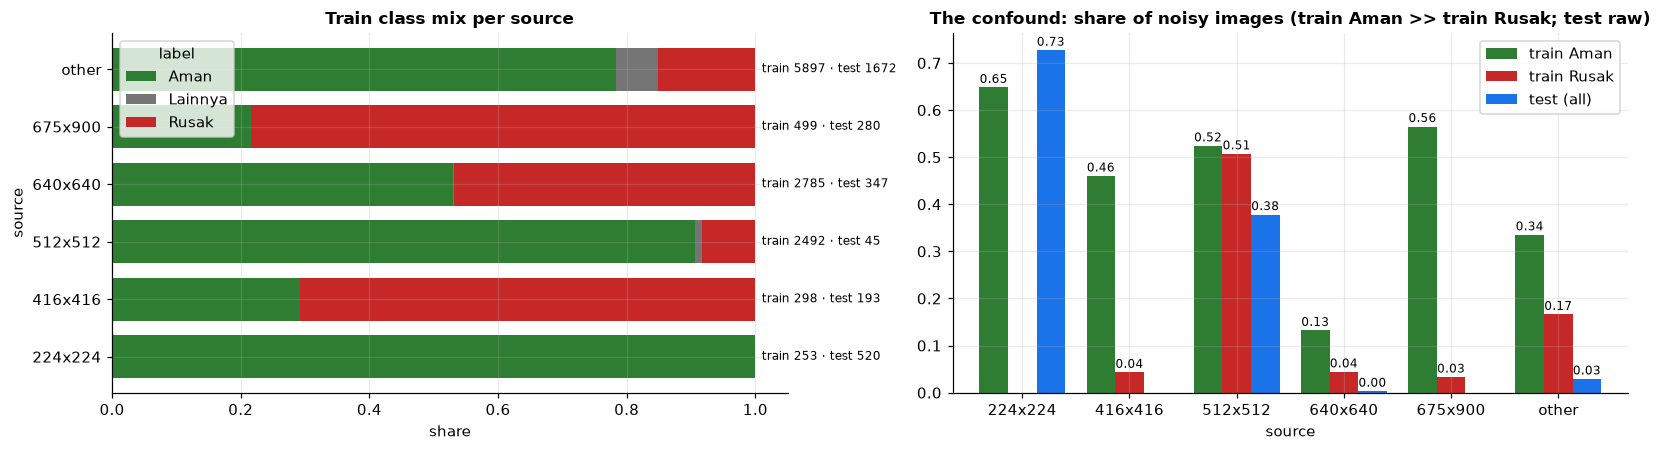

In [4]:
stage('eda')
meta = pd.read_csv(find('emb/meta_sorted.csv')); TR = (meta.split == 'train').values; TE = ~TR   # one row per image; every artifact shares this order
meta['size'] = meta.w.astype(str) + 'x' + meta.h.astype(str)
BIG = ['224x224', '416x416', '512x512', '640x640', '675x900']
meta['source'] = np.where(meta['size'].isin(BIG), meta['size'], 'other')                       # exact mapping used by every submitted rule
LAB = np.array([list(C).index(l) if isinstance(l, str) else -1 for l in meta.label])
nz = pd.read_csv(find('meta_noise.csv')).set_index('path').loc[meta.path]
meta['noisy'] = (nz.impulse.values > 0.02) | (nz.medabs.values >= 6)                            # salt-and-pepper or heavy residual noise
ST = np.where(meta.noisy, 'noisy', 'clean') + '_' + np.where(meta['size'] == '224x224', '224', 'other')   # noise strata used by post-processing
print('train', TR.sum(), '| test', TE.sum(), '| train class mix', meta[TR].label.value_counts(normalize=True).round(3).to_dict())
src = pd.DataFrame({'train_n': meta[TR].source.value_counts(), 'test_n': meta[TE].source.value_counts()}).fillna(0).astype(int)
src = src.join(pd.crosstab(meta[TR].source, meta[TR].label, normalize='index').round(3).add_prefix('train_'))
src = src.join(meta[TR].pivot_table(index='source', columns='label', values='noisy', aggfunc='mean').round(3).add_prefix('noisy|'))
src['noisy|test'] = meta[TE].groupby('source').noisy.mean().round(3); show(src)
if img_ok:
    rng = np.random.default_rng(0); fig, ax = plt.subplots(4, 8, figsize=(16, 8.4))
    for r, (name, sel) in enumerate([(c, TR & (meta.label == c).values) for c in C] + [('test', TE)]):
        for j, i in enumerate(rng.choice(np.where(sel)[0], 8, replace=False)):
            ax[r, j].imshow(Image.open(IMG / meta.path[i].split('work/small/')[1]).convert('RGB').resize((150, 150))); ax[r, j].set_title(f'{name} | {meta.source[i]}', fontsize=7); ax[r, j].axis('off')
    plt.suptitle('Random train images per class (rows 1-3) and test images (row 4)'); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
mix = pd.crosstab(meta[TR].source, meta[TR].label, normalize='index')[list(C)]
mix.plot.barh(stacked=True, ax=ax[0], color=[COL[c] for c in C], width=0.75); ax[0].set_title('Train class mix per source'); ax[0].set_xlabel('share')
for i, s_ in enumerate(mix.index): ax[0].text(1.01, i, f"train {src.loc[s_, 'train_n']} · test {src.loc[s_, 'test_n']}", va='center', fontsize=8)
nzt = pd.DataFrame({'train Aman': src['noisy|Aman'], 'train Rusak': src['noisy|Rusak'], 'test (all)': src['noisy|test']}).fillna(0)
nzt.plot.bar(ax=ax[1], color=[COL['Aman'], COL['Rusak'], COL['blue']], width=0.8, rot=0); ax[1].set_title('The confound: share of noisy images (train Aman >> train Rusak; test raw)'); annotate(ax[1])
plt.tight_layout(); plt.show()

## 2. Data cleaning: duplicates, near-copies, label noise
- **Pixel-exact copies.** Each image becomes a 128-px grayscale thumbnail with zero mean and unit norm. All 8 dihedral variants are compared with the top-10 SSCD copy-detector neighbours by NCC, and NCC ≥ 0.99 counts as an exact copy. This survives re-encoding, resizing, flips and rotations.
- **SSCD** (Pizzi et al., CVPR 2022) finds near-copies, including noisy, recoloured and cropped ones.
- **Label noise.** Train↔train exact copies agree on their label only ~96% of the time, which bounds achievable accuracy on copies. cleanlab (Confident Learning) on honest group-OOF probabilities is used as a diagnostic only: relabelling the flagged rows cost −0.019 on the LB.

== §2 cleaning | elapsed 0.1 min | planned remaining 14 min


train-train exact pairs 6439 | label agreement 0.9621
         size   mean
source              
224x224    21  1.000
416x416     8  1.000
512x512   118  0.958
640x640  4180  0.958
675x900    40  1.000
other    2072  0.970
test rows with an exact train copy: 796 (26.0%)
copy labels of test rows by source:
copy_label  Aman  CONFLICT  Lainnya  Rusak
source                                    
224x224       53         0        0      0
416x416       21         0        0      0
512x512        5         0        0      0
640x640       61        13        1    171
675x900       51         0        0      0
other        354         7        0     59


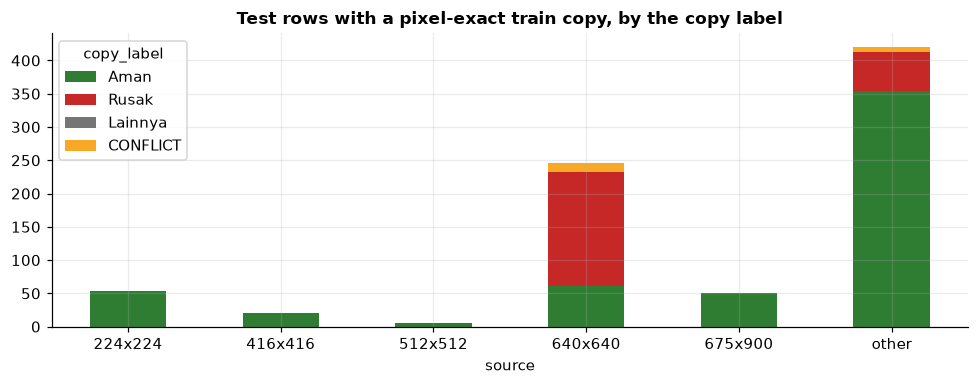

In [5]:
stage('cleaning')
D = np.load(find('nntr_sscd.npz')); I_sscd, S_sscd = D['i'], D['s']            # top-10 train neighbours by SSCD, self excluded
def thumb(path, n=128):
    a = np.asarray(Image.open(path).convert('L').resize((n, n), Image.BILINEAR), np.float32); a -= a.mean(); return a / (np.linalg.norm(a) + 1e-6)
def pixel_ncc(paths, cand, n=128):
    from concurrent.futures import ThreadPoolExecutor
    with ThreadPoolExecutor(8) as ex: TH = np.stack(list(ex.map(lambda p: thumb(p, n), paths)))
    DH = np.stack([np.rot90(b, k, axes=(1, 2)) for b in (TH, TH[:, :, ::-1]) for k in range(4)], 1); out = np.zeros(cand.shape, np.float32)
    for a in range(0, len(paths), 500):
        q = np.arange(a, min(a + 500, len(paths))); out[q] = np.einsum('qvd,qkd->qkv', DH[q].reshape(len(q), 8, -1), TH[cand[q]].reshape(len(q), cand.shape[1], -1)).max(2)
    return out
if RECOMPUTE_PIX:
    NCC = pixel_ncc([str(IMG / p.split('work/small/')[1]) for p in meta.path], I_sscd)
    ref = np.load(find('pix_all.npz'))['ncc'] if find('pix_all.npz', False) else None
    if ref is not None: print('recomputed NCC vs cached: max abs diff', float(np.abs(NCC - ref).max()))
else: NCC = np.load(find('pix_all.npz'))['ncc']          # [N, 10], meta_sorted order, aligned with nntr_sscd 'i' (work/pixall.py)
best = NCC.max(1); exact = best >= 0.99
rows = [(meta.source[r], LAB[r], LAB[I_sscd[r, k]]) for r in np.where(TR)[0] for k in np.where(NCC[r] >= 0.99)[0]]
tt = pd.DataFrame(rows, columns=['source', 'y', 'y_copy']); tt['agree'] = tt.y == tt.y_copy
print('train-train exact pairs', len(tt), '| label agreement', round(tt.agree.mean(), 4)); show(tt.groupby('source').agree.agg(['size', 'mean']).round(3))
print('test rows with an exact train copy:', int(exact[TE].sum()), f'({exact[TE].mean():.1%})')
te_idx = np.where(TE)[0]; copy_lab = {}
for r in te_idx:
    k = np.where(NCC[r] >= 0.99)[0]
    if len(k): labs = set(LAB[I_sscd[r, k]]); copy_lab[r] = labs.pop() if len(labs) == 1 else -2   # -2 = copies disagree
cs = pd.DataFrame([(meta.source[r], C[v] if v >= 0 else 'CONFLICT') for r, v in copy_lab.items()], columns=['source', 'copy_label'])
print('copy labels of test rows by source:'); ct = pd.crosstab(cs.source, cs.copy_label); show(ct)
ax = ct.reindex(columns=[c for c in ['Aman', 'Rusak', 'Lainnya', 'CONFLICT'] if c in ct.columns]).plot.bar(stacked=True, figsize=(9, 3.6), rot=0, color=[COL.get(c, COL['amber']) for c in ['Aman', 'Rusak', 'Lainnya', 'CONFLICT'] if c in ct.columns])
ax.set_title('Test rows with a pixel-exact train copy, by the copy label'); plt.tight_layout(); plt.show()

In [6]:
from cleanlab.filter import find_label_issues
y = LAB[TR]; fold = pd.read_csv(find('folds_group90.csv')).set_index('path').fold.loc[meta.path[TR]].values
def load_preds(tag, k_files=5):
    tr_paths = meta.path[TR].values; pos = {p: i for i, p in enumerate(tr_paths)}; tpos = {p: i for i, p in enumerate(meta.path[TE].values)}
    oof = np.full((TR.sum(), 3), np.nan); tst = np.zeros((TE.sum(), 3))
    for k in range(k_files):
        d = np.load(find(f'preds/{tag}/pred_{tag}_f{k}.npz'), allow_pickle=True); oof[[pos[p] for p in d['val_path']]] = d['val']; tst[[tpos[p] for p in d['test_path']]] += d['test']
    return oof, tst / k_files          # sum first, divide once: bit-identical to the pipeline that wrote the submitted files (the prior-match bisection is tie-sensitive)
oof_h2, test_h2 = load_preds('h2_peg_c11')
iss = find_label_issues(y, oof_h2, filter_by='both', n_jobs=1)
print('cleanlab flags', int(iss.sum()), 'of', len(y), 'train rows (diagnostic only; relabelling them lost 0.019 on LB)')
show(pd.crosstab(pd.Series(C[y[iss]], name='given'), pd.Series(C[oof_h2[iss].argmax(1)], name='model')))

cleanlab flags 437 of 12224 train rows (diagnostic only; relabelling them lost 0.019 on LB)
model    Aman  Lainnya  Rusak
given                        
Aman        0        7    144
Lainnya    14        0      0
Rusak     272        0      0


## 3. Data processing and validation design
- **Preprocessing** for every frozen tower: median 3×3 (removes the injected salt-and-pepper noise), then a bicubic squash to the tower's native size. Each geometric view is embedded and the embeddings are summed and L2-normalised.
- **Validation.** Random K-fold rewards memorising near-duplicates: OOF 0.897 against LB 0.786. Folds are therefore built from DINOv2 cosine ≥ 0.90 clusters plus exact MD5 matches (`work/make_folds.py`, StratifiedGroupKFold 5, seed 42). Check below: exact-copy train pairs should rarely straddle folds.

In [7]:
stage('processing')
TOWERS = [  # (timm name, native size, views) -- the 11 frozen towers behind h2 / DA heads (CAT6 + GIANT)
    ('vit_pe_core_large_patch14_336.fb', 336, ('orig',)), ('vit_so400m_patch16_siglip_384.v2_webli', 384, ('orig',)),
    ('vit_large_patch14_dinov2.lvd142m', 224, ('orig', 'hflip')), ('vit_large_patch14_clip_224.openai', 224, ('orig', 'hflip')),
    ('vit_huge_patch14_clip_224.dfn5b', 224, ('orig',)), ('eva02_large_patch14_clip_224.merged2b', 224, ('orig',)),
    ('vit_pe_core_gigantic_patch14_448.fb', 448, ('orig',)), ('eva02_enormous_patch14_clip_224.laion2b_plus', 224, ('orig',)),
    ('vit_huge_patch14_clip_378.metaclip2_worldwide', 378, ('orig',)), ('vit_giantopt_patch16_siglip_384.v2_webli', 384, ('orig',)),
    ('vit_gigantic_patch14_clip_378.metaclip2_worldwide', 378, ('orig',))]
CAT6, GIANT = [t[0].split('.')[0] for t in TOWERS[:6]], [t[0].split('.')[0] for t in TOWERS[6:]]
EMB = OUT / 'emb'
def extract(name, size, views):  # bf16 frozen features, median-3 + bicubic squash, summed geometric views (as kernels/emb*, colab/emb_giant.py)
    import torch, timm, cv2
    from torch.utils.data import Dataset, DataLoader
    class DS(Dataset):
        def __len__(s): return len(meta)
        def __getitem__(s, i):
            a = cv2.medianBlur(np.asarray(Image.open(IMG / meta.path[i].split('work/small/')[1]).convert('RGB')), 3)
            return torch.from_numpy(np.asarray(Image.fromarray(a).resize((size, size), Image.BICUBIC)).copy()).permute(2, 0, 1)
    m = timm.create_model(name, pretrained=True, num_classes=0).eval().cuda().to(torch.bfloat16); cfg = timm.data.resolve_data_config({}, model=m)
    mean, std = [torch.tensor(cfg[k], device='cuda').view(1, 3, 1, 1) for k in ('mean', 'std')]; V = {v: [] for v in views}
    with torch.no_grad():
        for x in DataLoader(DS(), batch_size=64, num_workers=8):
            x = ((x.cuda().float() / 255 - mean) / std).to(torch.bfloat16)
            for v in views: V[v].append(m({'orig': x, 'hflip': x.flip(3)}[v]).float().cpu().numpy())
    np.savez(EMB / f"emb_{name.split('.')[0]}.npz", **{v: np.concatenate(a).astype(np.float16) for v, a in V.items()}); del m; torch.cuda.empty_cache()
if RECOMPUTE_EMB:
    EMB.mkdir(exist_ok=True)
    for name, size, views in TOWERS:
        t = time.time(); extract(name, size, views); print('embedded', name, f'{time.time() - t:.0f}s', flush=True)
fpos = dict(zip(meta.path[TR], fold))
pairs = [(fpos[meta.path[r]], fpos[meta.path[I_sscd[r, k]]]) for r in np.where(TR)[0] for k in np.where(NCC[r] >= 0.99)[0]]
print('fold sizes', np.bincount(fold).tolist(), '| exact-copy train pairs crossing folds:', f'{np.mean([a != b for a, b in pairs]):.2%}', 'of', len(pairs))

== §3 processing | elapsed 0.3 min | planned remaining 12 min


fold sizes [2445, 2445, 2445, 2445, 2444] | exact-copy train pairs crossing folds: 6.71% of 6439


## 4. Augmentation
Fine-tune augmentation (`kernels/ft/ft.py`, recipe `d8`), applied to both classes:
- RandomResizedCrop(0.4–1), horizontal and vertical flips, a random quarter-turn (the dihedral group, matching the d8 TTA);
- ColorJitter(0.3, 0.3, 0.3, 0.05) and grayscale (p 0.1);
- organiser-style corruption on 30% of images: impulse noise, or Gaussian noise with σ 5–40;
- a low-res round trip on 20% of images.

**Closed variant `augeq`** (session 11): corrupt every train image and every TTA view, so that "raw vs augmented" carries no label. It did not reduce the shortcut (G1n 0.515 vs 0.476) and was dropped.

In [8]:
stage('augmentation')
if img_ok:
    import torch, torchvision.transforms.v2 as T
    S = 256; base = T.Compose([T.RandomResizedCrop(S, scale=(0.4, 1), ratio=(0.6, 1.66)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(0.5),
                               T.Lambda(lambda x: torch.rot90(x, int(np.random.randint(4)), (-2, -1))), T.ColorJitter(0.3, 0.3, 0.3, 0.05), T.RandomGrayscale(0.1)])
    def corrupt(im):
        a = np.asarray(im).astype(np.float32); r = np.random.rand()
        if r < 0.5: msk = np.random.rand(*a.shape[:2]); p = np.random.uniform(0.01, 0.1); a[msk < p / 2] = 0; a[msk > 1 - p / 2] = 255
        else: a = a + np.random.randn(*a.shape) * np.random.uniform(5, 40)
        return Image.fromarray(a.clip(0, 255).astype(np.uint8))
    np.random.seed(1); torch.manual_seed(1); i = np.where(TR & (meta.label == 'Rusak').values)[0][7]
    im = Image.open(IMG / meta.path[i].split('work/small/')[1]).convert('RGB'); fig, ax = plt.subplots(1, 8, figsize=(16, 2.4))
    ax[0].imshow(im.resize((S, S))); ax[0].set_title('original', fontsize=8)
    for j in range(1, 8):
        x = base(T.functional.to_image(corrupt(im) if j % 3 == 0 else im)); ax[j].imshow(x.permute(1, 2, 0).numpy()); ax[j].set_title('augmented', fontsize=8)
    for a in ax: a.axis('off')
    plt.tight_layout(); plt.show()

== §4 augmentation | elapsed 0.3 min | planned remaining 11 min


## 5. Model I: 11 frozen vision towers + MLP heads (h2)
- **Towers:** PE-Core-L/G, SigLIP2-so400m/giant, DINOv2-L, CLIP-L, DFN5B CLIP-H, EVA02-CLIP-L/E, MetaCLIP2-H/G.
- **Head:** Dropout 0.5 → Linear 512 → GELU → Dropout 0.3 → Linear 3; AdamW, OneCycle 40 epochs, label smoothing 0.1.
- **h2** = geometric mean of two feature sets (CAT6 + PE-G, and all 11) × 5 seeds.
- In the ablations, fine-tuning L-size backbones always trailed this frozen ensemble on group-OOF. The H+ fine-tune in §9 is the exception that matters on test.

== §5 model1 | elapsed 0.3 min | planned remaining 10 min


h2 group-OOF macro-F1 vs original labels 0.8926 | per class [0.936 0.955 0.787]
              pred Aman  pred Lainnya  pred Rusak
true Aman          8544             8         248
true Lainnya         28           394           1
true Rusak          892             0        2109
    source     n  OOF macro-F1
0  224x224   253        1.0000
1  416x416   298        0.6344
2  512x512  2492        0.7691
3  640x640  2785        0.5564
4  675x900   499        0.9073
5    other  5897        0.8907


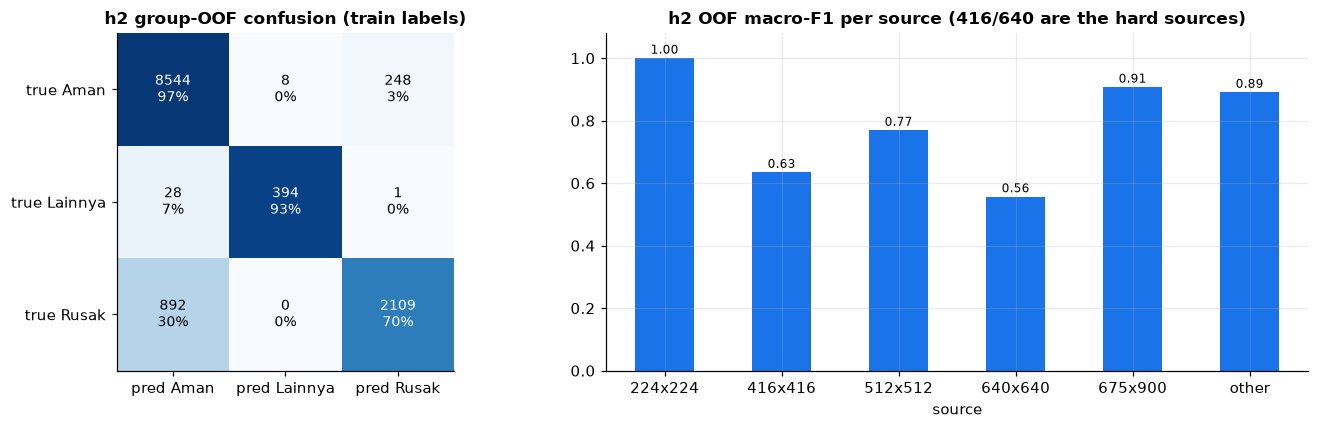

In [9]:
stage('model1')
f1m = lambda yt, p: round(f1_score(yt, p, average='macro'), 4)
print('h2 group-OOF macro-F1 vs original labels', f1m(y, oof_h2.argmax(1)), '| per class', f1_score(y, oof_h2.argmax(1), average=None).round(3))
show(pd.DataFrame(confusion_matrix(y, oof_h2.argmax(1)), index=[f'true {c}' for c in C], columns=[f'pred {c}' for c in C]))
s_tr = meta.source.values[TR]
per_src = pd.DataFrame([(s, int((s_tr == s).sum()), f1m(y[s_tr == s], oof_h2[s_tr == s].argmax(1))) for s in BIG + ['other']], columns=['source', 'n', 'OOF macro-F1']); show(per_src)
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); cm = confusion_matrix(y, oof_h2.argmax(1)); cmn = cm / cm.sum(1, keepdims=True)
ax[0].imshow(cmn, cmap='Blues', vmin=0, vmax=1); ax[0].grid(False); ax[0].set_xticks(range(3), [f'pred {c}' for c in C]); ax[0].set_yticks(range(3), [f'true {c}' for c in C])
for i in range(3):
    for j in range(3): ax[0].text(j, i, f'{cm[i, j]}\n{cmn[i, j]:.0%}', ha='center', va='center', color='white' if cmn[i, j] > 0.5 else 'black', fontsize=9)
ax[0].set_title('h2 group-OOF confusion (train labels)')
per_src.set_index('source')['OOF macro-F1'].plot.bar(ax=ax[1], color=COL['blue'], rot=0); annotate(ax[1]); ax[1].set_ylim(0, 1.08); ax[1].set_title('h2 OOF macro-F1 per source (416/640 are the hard sources)')
plt.tight_layout(); plt.show()

## 6. Pseudo-labels: twin lock + domain-adapted (DA) heads
1. **Twin vote.** Each test row takes a similarity-weighted vote of its SSCD train twins with sim ≥ 0.55. It is **locked** to the vote when purity ≥ 0.9 and the row is in the clean, non-224 stratum. Train leave-one-out accuracy of this rule is 0.981.
2. **DA heads.** The h2 heads are retrained on train plus the locked test rows (2 feature sets × 5 seeds), so they see the test-domain shift.
3. **Validation on the test domain.** Locked test rows are split into 5 folds by SSCD-twin connected components and evaluated held out (`work/pl_iter.py`). Iterating the pseudo-labels for more rounds added < 0.005 and was closed.

== §6 pseudo | elapsed 0.3 min | planned remaining 9 min


twin-locked test rows 1534 | label mix {'Aman': 1052, 'Rusak': 476, 'Lainnya': 6}
iterative pseudo-labelling, held-out locked test rows:
   round  heldout_f1  heldout_f1_b08  unlocked_rusak_b08  pseudo_rows
0      0      0.9604          0.9814               0.262            0
1      1      0.9613          0.9809               0.262          749
2      2      0.9628          0.9824               0.263          806
3      3      0.9613          0.9824               0.263          829


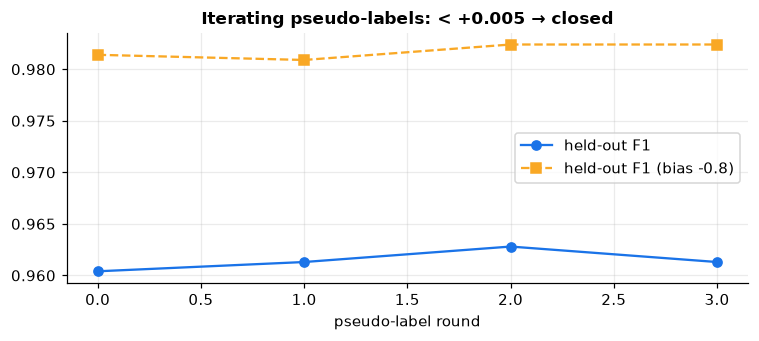

In [10]:
stage('pseudo')
def vote(I, S, thr):
    w = np.where(S >= thr, S, 0.0); P = np.stack([(w * (LAB[I] == c)).sum(1) for c in range(3)], 1); tot = P.sum(1)
    return np.where(tot > 0, P.argmax(1), -1), np.where(tot > 0, P.max(1) / np.maximum(tot, 1e-9), 0)
te = np.where(TE)[0]; lab_t, pur_t = vote(I_sscd[te], S_sscd[te], 0.55); lock_t = (lab_t >= 0) & (pur_t >= 0.9) & (ST[te] == 'clean_other')
print('twin-locked test rows', int(lock_t.sum()), '| label mix', pd.Series(C[lab_t[lock_t]]).value_counts().to_dict())
_, t_da = load_preds('da_h2')
if RETRAIN_HEADS:  # same recipe as work/da_heads.py
    import torch, torch.nn as nn, torch.nn.functional as F
    dev = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
    def feat(t):
        E = np.load(EMB / f'emb_{t}.npz' if RECOMPUTE_EMB else find(f'emb/emb_{t}.npz')); X = sum(E[k].astype(np.float32) for k in E.files); return X / np.linalg.norm(X, axis=1, keepdims=True)
    def fit(X, idx, yy, seed, ep=40):
        torch.manual_seed(seed); Xa = X[idx]
        m = nn.Sequential(nn.Dropout(0.5), nn.Linear(X.shape[1], 512), nn.GELU(), nn.Dropout(0.3), nn.Linear(512, 3)).to(dev)
        opt = torch.optim.AdamW(m.parameters(), 1e-3, weight_decay=1e-2); sch = torch.optim.lr_scheduler.OneCycleLR(opt, 1e-3, total_steps=ep * ((len(yy) + 255) // 256))
        for _ in range(ep):
            for b in torch.randperm(len(yy), device=dev).split(256):
                loss = F.cross_entropy(m(Xa[b]), yy[b], label_smoothing=0.1); opt.zero_grad(); loss.backward(); opt.step(); sch.step()
        return m.eval()
    idx = np.r_[np.where(TR)[0], te[lock_t]]; yy = torch.tensor(np.r_[LAB[TR], lab_t[lock_t]], device=dev); Ls = []
    for towers in (CAT6 + GIANT[:1], CAT6 + GIANT):
        X = torch.tensor(np.concatenate([feat(t) for t in towers], 1), device=dev); P = 0
        for s in range(5):
            m = fit(X, idx, yy, s)
            with torch.no_grad(): P = P + m(X[te]).softmax(1).cpu().numpy() / 5
        Ls.append(np.log(P + 1e-9))
    t_new = np.exp(np.mean(Ls, 0)); t_new /= t_new.sum(1, keepdims=True)
    print(f'RETRAIN_HEADS ({dev}): argmax agreement with the cached DA heads {np.mean(t_new.argmax(1) == t_da.argmax(1)):.4f}'); t_da = t_new
pl = find('pl_iter_scores.csv', False); print('iterative pseudo-labelling, held-out locked test rows:'); show(pd.read_csv(pl) if pl else 'pl_iter_scores.csv not available')
if pl:
    d_ = pd.read_csv(pl); fig, ax = plt.subplots(figsize=(7, 3.2)); ax.plot(d_['round'], d_.heldout_f1, 'o-', color=COL['blue'], label='held-out F1'); ax.plot(d_['round'], d_.heldout_f1_b08, 's--', color=COL['amber'], label='held-out F1 (bias -0.8)')
    ax.set_xlabel('pseudo-label round'); ax.set_title('Iterating pseudo-labels: < +0.005 → closed'); ax.legend(); plt.tight_layout(); plt.show()

## 7. Post-processing → `d04_da_bt2` (public LB 0.84521)
- Locked rows keep their twin label.
- No-twin clean rows get a Rusak logit bias of −0.8, cross-validated on the held-out locked rows.
- Mixed-vote rows get a Rusak share calibrated from train vote bins.
- Other strata are matched to the train P(Rusak | stratum) (Saerens et al. 2002 quantification).

In [11]:
stage('postproc')
def match(L, st, ytr, sttr, targets, min_n=50):
    L = L.copy()
    for s in np.unique(st):
        m = st == s; tgt = targets.get(s, (ytr[sttr == s] == 2).mean() if (sttr == s).any() else None)
        if tgt is None or m.sum() < min_n or tgt == 0: continue
        lo, hi = -8.0, 8.0
        for _ in range(60):
            b = (lo + hi) / 2
            if ((L[m] + np.r_[0, 0, b]).argmax(1) == 2).mean() < tgt: lo = b
            else: hi = b
        L[m, 2] += (lo + hi) / 2
    return L
def build_da_bt2(test_probs, thr=0.55, purity=0.9, bstar=-0.8):
    lab, pur = vote(I_sscd[te], S_sscd[te], thr); lock = (lab >= 0) & (pur >= purity) & (ST[te] == 'clean_other')
    L = np.log(test_probs + 1e-9); ytr, sttr = LAB[TR], ST[TR]; final = L.argmax(1).copy(); tg = {}
    u = ~lock & (ST[te] == 'clean_other'); bt_share = float(((L[u] + np.r_[0, 0, bstar]).argmax(1) == 2).mean())
    for s in np.unique(ST[te]):
        m = ST[te] == s; T_ = {'clean_other': 0.381}.get(s, (ytr[sttr == s] == 2).mean()); n_l = (m & lock).sum()
        tg[s] = float(np.clip((T_ * m.sum() - (lab[m & lock] == 2).sum()) / max((m & ~lock).sum(), 1), 0, 1)) if n_l else T_
        if s == 'clean_other': tg[s] = bt_share
    stu = ST[te].astype(object).copy(); Itr, Str = I_sscd[TR], S_sscd[TR]; lt, pt = vote(Itr, Str, thr)
    def wr(I_, S_): w = np.where(S_ >= thr, S_, 0); return (w * (LAB[I_] == 2)).sum(1) / np.maximum(w.sum(1), 1e-9)
    mtr = (lt >= 0) & (pt < 0.9) & (ST[TR] == 'clean_other'); rtr = wr(Itr, Str); edges = [0, 0.3, 0.5, 0.7, 1.01]
    cal = [float((LAB[TR][mtr & (rtr >= a) & (rtr < b)] == 2).mean()) for a, b in zip(edges[:-1], edges[1:])]
    mix = (lab >= 0) & ~lock & (ST[te] == 'clean_other'); nt = (lab < 0) & (ST[te] == 'clean_other'); rte = wr(I_sscd[te], S_sscd[te])
    stu[mix] = 'co_mixed'; stu[nt] = 'co_notwin'
    tg['co_mixed'] = float(np.mean([cal[np.searchsorted(edges, r, 'right') - 1] for r in rte[mix]])); tg['co_notwin'] = float(((L[nt] + np.r_[0, 0, bstar]).argmax(1) == 2).mean())
    final[~lock] = match(L[~lock], stu[~lock].astype(str), ytr, sttr, tg).argmax(1); final[lock] = lab[lock]
    print(f'locked {lock.sum()} | Rusak targets', {k: round(v, 3) for k, v in tg.items()}); return final
ss = pd.read_csv(find('sample_submission.csv')); stem2fn = {f.rsplit('.', 1)[0]: f for f in ss.filename}
TEST_FN = np.array([stem2fn[p.split('/')[-1][:-4]] for p in meta.path[TE]])
def to_sub(labels):  # labels aligned to meta test order -> submission in sample_submission order
    sub = ss[['filename']].merge(pd.DataFrame({'filename': TEST_FN, 'label': labels}), on='filename', how='left'); assert sub.label.notna().all() and set(sub.label) <= set(C); return sub
def check(name, labels):
    ref = pd.read_csv(find(f'{name}.csv')).set_index('filename').label.reindex(TEST_FN).values; same = float((ref == labels).mean())
    if not (RETRAIN_HEADS or RECOMPUTE_PIX): assert same == 1.0, f'{name} not reproduced ({same:.4f})'
    print(f'{name}: {"reproduced row-for-row" if same == 1 else f"agreement {same:.4f} (retrained parts differ by seed/device)"} | mix', pd.Series(labels).value_counts(normalize=True).round(3).to_dict())
SUBS = {}
SUBS['d04_da_bt2'] = C[build_da_bt2(t_da)]; check('d04_da_bt2', SUBS['d04_da_bt2'])

== §7 postproc | elapsed 0.3 min | planned remaining 8 min


locked 1534 | Rusak targets {np.str_('clean_224'): np.float64(0.0), np.str_('clean_other'): 0.421, np.str_('noisy_224'): np.float64(0.0), np.str_('noisy_other'): np.float64(0.096), 'co_mixed': 0.555, 'co_notwin': 0.299}
d04_da_bt2: reproduced row-for-row | mix {'Aman': 0.708, 'Rusak': 0.274, 'Lainnya': 0.018}


## 8. LB-anchored source rules
Each probe changes one source only, so its LB delta reads that source's true class mix.

| probe | change vs `d04_da_bt2` | public LB | read |
|---|---|---|---|
| `d05_p416_allA` | all 136 Rusak predictions in 416 → Aman | **0.87739 (+0.032)** | ≈ every flipped row is Aman: the test 416 boxes are intact |
| `d05_p675_R` | 158 no-copy 675 Aman → Rusak | 0.80201 (−0.043) | they are Aman: the DA lock was right |

`d06_cur_A` extends the confirmed finding to the 25 remaining Rusak predictions in the curated sources (512, 675). The **montage below** explains the 416 result: train Rusak = raw renders of dented boxes, train Aman = organiser-augmented images, test = raw intact boxes.

In [12]:
stage('rules')
src_te = meta.source.values[te]
p416 = SUBS['d04_da_bt2'].copy(); p416[(src_te == '416x416') & (p416 == 'Rusak')] = 'Aman'; SUBS['d05_p416_allA'] = p416; check('d05_p416_allA', p416)
p675 = SUBS['d04_da_bt2'].copy(); p675[(src_te == '675x900') & (best[te] <= 0.8) & (p675 == 'Aman')] = 'Rusak'; SUBS['d05_p675_R'] = p675; check('d05_p675_R', p675)
cur = p416.copy(); cur[np.isin(src_te, ['512x512', '675x900']) & (cur == 'Rusak')] = 'Aman'; SUBS['d06_cur_A'] = cur; check('d06_cur_A', cur)
if img_ok:
    rng = np.random.default_rng(0); groups = [('test 416 (LB: all Aman)', te[(src_te == '416x416') & (SUBS['d04_da_bt2'] == 'Rusak')]),
                                              ('train 416 Rusak', np.where(TR & (meta.source == '416x416').values & (LAB == 2))[0]),
                                              ('train 416 Aman', np.where(TR & (meta.source == '416x416').values & (LAB == 0))[0])]
    fig, ax = plt.subplots(3, 8, figsize=(16, 6.4))
    for r, (t, ix) in enumerate(groups):
        for j, i in enumerate(rng.choice(ix, 8, replace=False)): ax[r, j].imshow(Image.open(IMG / meta.path[i].split('work/small/')[1]).convert('RGB').resize((150, 150))); ax[r, j].axis('off')
        ax[r, 0].set_title(t, fontsize=9, loc='left')
    plt.suptitle('The augmentation shortcut: augmented = Aman, raw = Rusak in train; every test image is raw'); plt.tight_layout(); plt.show()

== §8 rules | elapsed 0.3 min | planned remaining 7 min


d05_p416_allA: reproduced row-for-row | mix {'Aman': 0.752, 'Rusak': 0.23, 'Lainnya': 0.018}
d05_p675_R: reproduced row-for-row | mix {'Aman': 0.656, 'Rusak': 0.326, 'Lainnya': 0.018}
d06_cur_A: reproduced row-for-row | mix {'Aman': 0.761, 'Rusak': 0.221, 'Lainnya': 0.018}


## 9. Model II (re-modelling): DINOv3-H+ full fine-tune
**Recipe** (pig-posture public 1st place):
- `vit_huge_plus_patch16_dinov3.lvd1689m` @384, batch 24, gradient checkpointing;
- AdamW lr 3e-5 with the head at ×10, uniform layer decay;
- cosine schedule with 5% warmup, 12 epochs;
- EMA 0.9985, label smoothing 0.1, drop-path 0.1;
- final EMA weights, 8-view dihedral TTA.

**Two-sided gate on test rows the LB has confirmed** (pre-registered; fold-0 models, train-only):
- `G1n` = 233 LB-confirmed Aman rows (416/675) with no train copy. A lower Rusak rate is better.
- `CRx` = 244 rows whose exact train copies unanimously say Rusak. A higher Rusak rate is better.

| model | G1n Rusak | CRx Rusak | 640 Rusak | gate |
|---|---|---|---|---|
| h2 frozen | 0.923 | 0.967 | 0.810 | — |
| h3A H+ `d8` | **0.476** | 0.922 | 0.781 | PASS |
| h3B H+ `d8` + locked test | 0.399 | 0.943 | 0.767 | (sees test rows) |
| h4H H+ `augeq` | 0.515 | 0.963 | 0.795 | FAIL |

**Final model F1:** h3A's recipe, `full_fit` on all 12,224 train rows plus 1,807 pseudo-labelled test rows. These are the 1,534 twin-locked rows, and every 416/675 test row set to Aman as the LB confirmed (overriding twin labels). `DS_RETRAIN_FT=1` retrains it (~2 h on an A100).

== §9 model2 | elapsed 0.3 min | planned remaining 6 min


{'G1 all (LB: Aman)': 480, 'G1n no copy (LB: Aman)': 339, 'CRx copy says Rusak': 230, 'CAx copy says Aman': 473, '640': 347, 'other': 1672, 'all': 3057}
                                        Rusak | G1 all (LB: Aman)  Rusak | G1n no copy (LB: Aman)  Rusak | CRx copy says Rusak  Rusak | CAx copy says Aman  Rusak | 640  Rusak | other  Rusak | all
h2 frozen (train-only)                                      0.925                           0.938                        0.991                       0.034        0.810          0.288        0.395
DA heads (+ locked test)                                    0.490                           0.522                        0.991                       0.015        0.810          0.262        0.313
F1 H+ full-fit + pseudo (sees G1 rows)                      0.056                           0.053                        0.996                       0.002        0.781          0.261        0.244
reading: lower on G1/G1n (truly Aman) is better; CRx should sta

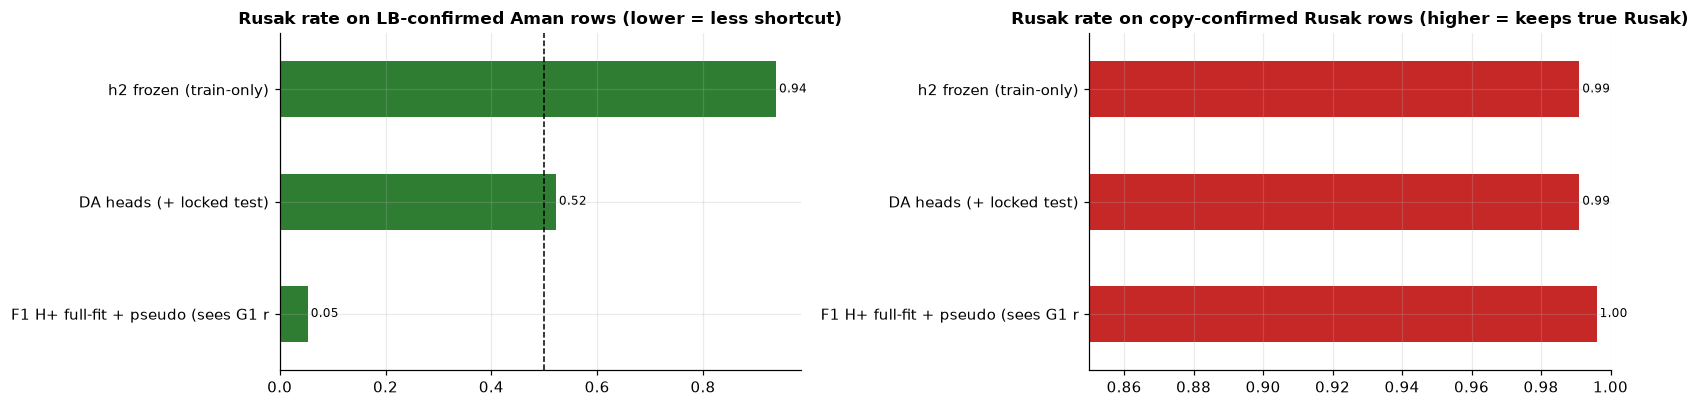

In [13]:
stage('model2')
if RETRAIN_FT:
    ps_te = te[lock_t]; g1 = te[np.isin(src_te, ['416x416', '675x900']) | (meta['size'].values[te] == '900x675')]
    ps = pd.DataFrame({'path': meta.path.values[ps_te], 'y': lab_t[lock_t]}); ps = pd.concat([ps[~ps.path.isin(meta.path.values[g1])], pd.DataFrame({'path': meta.path.values[g1], 'y': 0})])
    ext = Path('/content/in/extra' if COLAB else OUT / 'extra'); ext.mkdir(parents=True, exist_ok=True)
    pf_ = pd.DataFrame(np.eye(3)[ps.y.values], columns=list(C)); pf_.insert(0, 'path', ps.path.values); pf_.to_csv(ext / 'pseudo_final.csv', index=False)
    pd.read_csv(find('folds_group90.csv')).to_csv(ext / 'folds_group90.csv', index=False); shutil.copy(find('emb/meta_sorted.csv'), ext / 'meta_sorted.csv')
    cfg = dict(model='vit_huge_plus_patch16_dinov3.lvd1689m', img=384, epochs=12, sched='cosine', warm=0.05, lr=3e-5, head_mult=10, layer_decay=1.0, ema=0.9985, ls=0.1,
               bs=24, dpr=0.1, gc=True, folds=[0], fold_file='folds_group90.csv', save_w=True, median=True, full_fit=True, pseudo_file='pseudo_final.csv', aug='d8', tta='d8', tag='F1')
    env = dict(os.environ, CFG=json.dumps(cfg), DS_OUT=str(OUT), DS_IN='/content/in' if COLAB else str(ext.parent), NW='10')
    r = subprocess.run([sys.executable, '-u', str(FT_SCRIPT)], env=env); assert r.returncode == 0, 'fine-tune failed (see the log above)'
tpos = {p: i for i, p in enumerate(meta.path[TE].values)}
def load_ft(f):  # fine-tune test predictions (any subset of rows) -> (n_test, 3) in meta test order, NaN where absent
    z = np.load(f, allow_pickle=True); P = np.full((TE.sum(), 3), np.nan); P[[tpos[p] for p in z['test_path']]] = z['test']; return P
f_F1 = OUT / 'pred_F1_f0.npz' if RETRAIN_FT else find('pred_F1_f0.npz', False); P_F1 = load_ft(f_F1) if f_F1 else None
cl = np.array([copy_lab.get(r, -1) for r in te]); g1m = np.isin(src_te, ['416x416', '675x900']) | (meta['size'].values[te] == '900x675')
SETS = {'G1 all (LB: Aman)': g1m, 'G1n no copy (LB: Aman)': g1m & (best[te] < 0.95), 'CRx copy says Rusak': (cl == 2) & ~g1m, 'CAx copy says Aman': (cl == 0) & ~g1m,
        '640': src_te == '640x640', 'other': src_te == 'other', 'all': np.ones(len(te), bool)}
print({k: int(m.sum()) for k, m in SETS.items()})
def rates(P):
    ok = ~np.isnan(P[:, 0]); lab = np.nan_to_num(P).argmax(1)
    return {k: round(float((lab[m & ok] == 2).mean()), 3) if (m & ok).any() else np.nan for k, m in SETS.items()}
MODELS = {'h2 frozen (train-only)': test_h2, 'DA heads (+ locked test)': t_da}
for n, f in [('h3A H+ d8 fold0 (train-only)', 'pred_h3A_f0.npz'), ('h3B H+ d8 fold0 (+ locked test)', 'pred_h3B_f0.npz'), ('h4H H+ augeq fold0 (train-only)', 'pred_h4H_f0.npz')]:
    if find(f, False) is not None: MODELS[n] = load_ft(find(f))
if P_F1 is not None: MODELS['F1 H+ full-fit + pseudo (sees G1 rows)'] = P_F1
else: print('pred_F1_f0.npz not found (it lives in Drive datascape_2026/session12): F1 rows skipped')
GT = pd.DataFrame({n: rates(P) for n, P in MODELS.items()}).T.add_prefix('Rusak | '); show(GT)
print('reading: lower on G1/G1n (truly Aman) is better; CRx should stay high. Train-only models are the fair gate; F1 trains on G1 rows, so its G1 numbers are in-sample.')
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8)); gt = GT.copy(); gt.index = [i[:34] for i in gt.index]
gt['Rusak | G1n no copy (LB: Aman)'].plot.barh(ax=ax[0], color=COL['Aman']); ax[0].invert_yaxis(); ax[0].axvline(0.5, ls='--', c='k', lw=1); annotate(ax[0], horizontal=True)
ax[0].set_title('Rusak rate on LB-confirmed Aman rows (lower = less shortcut)')
gt['Rusak | CRx copy says Rusak'].plot.barh(ax=ax[1], color=COL['Rusak']); ax[1].invert_yaxis(); ax[1].set_xlim(0.85, 1.0); annotate(ax[1], horizontal=True)
ax[1].set_title('Rusak rate on copy-confirmed Rusak rows (higher = keeps true Rusak)'); plt.tight_layout(); plt.show()

## 10. Ensemble, TTA and candidates
TTA:
- frozen towers: summed geometric views (§3);
- DA heads: geometric mean of 2 feature sets × 5 seeds;
- F1: 8-view dihedral TTA.

**Candidates** start from `d06_cur_A`. They only touch rows that meet all of these:
- in 640/other;
- no pixel copy in train (NCC < 0.95);
- F1 disagrees with confidence ≥ 0.70.

Two variants:
- `F1_RA`: Rusak → Aman only. The shortcut biases every model towards Rusak, so F1 calling Aman against that bias is the more trustworthy direction.
- `F1_both`: both directions.

In [14]:
stage('candidates')
if P_F1 is None: print('no F1 predictions -> no F1 candidates (see FUTURE_WORK.md)')
else:
    elig = np.isin(src_te, ['640x640', 'other']) & ~g1m & (best[te] < 0.95)        # 640/other rows with no pixel copy in train
    labF = C[np.nan_to_num(P_F1).argmax(1)]; confF = np.nan_to_num(P_F1).max(1); base_lab = SUBS['d06_cur_A']
    for var, extra in [('RA', (base_lab == 'Rusak') & (labF == 'Aman')), ('both', np.ones(len(te), bool))]:
        flip = ~np.isnan(P_F1[:, 0]) & elig & (labF != base_lab) & (confF >= 0.70) & extra; SUBS[f'cand_F1_{var}'] = np.where(flip, labF, base_lab)
        print(f'cand_F1_{var}: {int(flip.sum())} flips |', pd.Series([f'{s}:{a}>{b}' for s, a, b in zip(src_te[flip], base_lab[flip], labF[flip])]).value_counts().to_dict(),
              '| Rusak share', round(float((SUBS[f'cand_F1_{var}'] == 'Rusak').mean()), 3))

== §10 candidates | elapsed 0.3 min | planned remaining 5 min


cand_F1_RA: 6 flips | {'other:Rusak>Aman': 6} | Rusak share 0.219
cand_F1_both: 31 flips | {'other:Aman>Rusak': 25, 'other:Rusak>Aman': 6} | Rusak share 0.228


## 11. Error analysis
1. **LB history:** expected vs actual for every submission of this pipeline.
2. **Paired probe reads:** `work/lbdelta.py` enumerates the public confusion states consistent with the base score. It integrates the number of public rows among the flipped ones over Binomial(n, 0.3) and returns the probe LB as a function of q, the share of flipped rows that are truly Rusak.
3. **Joint LB inversion** of the three scores (base, +416, +675) into per-class public F1.

== §11 errors | elapsed 0.3 min | planned remaining 4 min


                     name  expected_lb  exp_lo  exp_hi  actual_lb  delta_vs_expected
0   r1003_calib_knn_probe        0.799   0.783   0.815    0.78627           -0.01273
1          r1003_clean_v1        0.786   0.770   0.802    0.76761           -0.01839
10             d04_da_bt2        0.930   0.890   0.960    0.84521           -0.08479
11     d05_h2_nolock_s337        0.845   0.800   0.880    0.83004           -0.01496
15          d05_p416_allA        0.850   0.810   0.880    0.87739            0.02739
17             d05_p675_R        0.855   0.810   0.880    0.80201           -0.05299


                                 q=0.0   q=0.2   q=0.5   q=0.8   q=1.0
d05_p416_allA (actual 0.87739)  0.8775  0.8572  0.8373  0.8178  0.7980
d05_p675_R (actual 0.80201)     0.8110  0.8316  0.8517  0.8714  0.8907
d06_cur_A vs p416 (pending)     0.8837  0.8798  0.8760  0.8723  0.8684


  implied (public, base d04)     mean       5%      95%
0                    F1 Aman    0.885    0.764    0.971
1                   F1 Rusak    0.808    0.703    0.896
2                 F1 Lainnya    0.843    0.710    0.971
3          true public Rusak  217.640  169.735  265.970
4        true public Lainnya   17.347   11.286   25.121
    source     n  OOF: true A pred R  true R pred A  Lainnya errors
0  224x224   253                   0              0               0
1  416x416   298                   6            102               0
2  512x512  2492                  32            124               8
3  640x640  2785                  93            355               3
4  675x900   499                  13             19               0
5    other  5897                 104            292              26


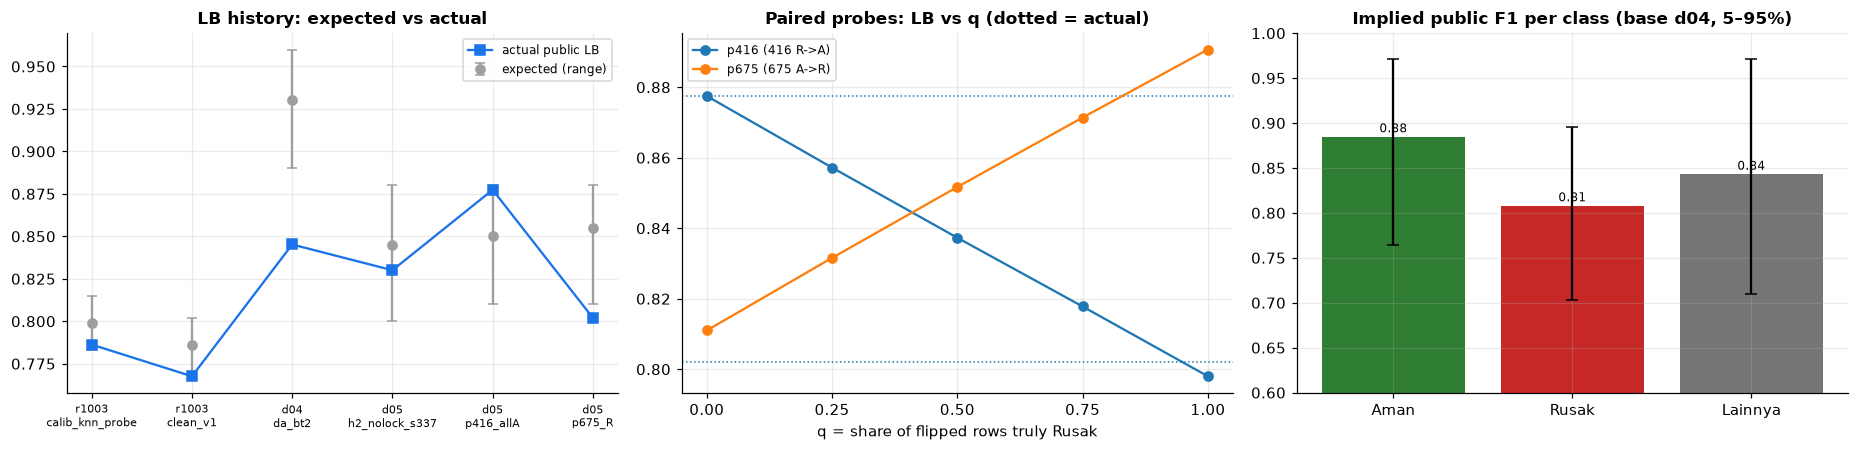

In [15]:
stage('errors')
led = pd.read_csv(find('ledger.csv')); show(led[led.actual_lb.notna()][['name', 'expected_lb', 'exp_lo', 'exp_hi', 'actual_lb', 'delta_vs_expected']])
import importlib.util; spec = importlib.util.spec_from_file_location('lbdelta', find('lbdelta.py')); lbd = importlib.util.module_from_spec(spec); spec.loader.exec_module(lbd)
def read_probe(base, probe, S0):
    b, p = pd.Series(SUBS[base]), pd.Series(SUBS[probe]); up = int(((b == 'Aman') & (p == 'Rusak')).sum()); dn = int(((b == 'Rusak') & (p == 'Aman')).sum())
    pA, pR = [round(0.3 * (b == c).sum()) for c in ('Aman', 'Rusak')]; st = lbd.states(pA, pR, S0)
    return {f'q={q:.1f}': round(lbd.curve(pA, pR, st, up, dn, q, q)[0], 4) for q in (0, 0.25, 0.5, 0.75, 1)}
show(pd.DataFrame({'d05_p416_allA (actual 0.87739)': read_probe('d04_da_bt2', 'd05_p416_allA', 0.84521), 'd05_p675_R (actual 0.80201)': read_probe('d04_da_bt2', 'd05_p675_R', 0.84521),
                   'd06_cur_A vs p416 (pending)': read_probe('d05_p416_allA', 'd06_cur_A', 0.87739)}).T)
from scipy.stats import binom
S0, S1, S2 = 0.84521, 0.87739, 0.80201; pA, pR, pL = 649, 251, 16; N = 917; out = []   # base / +416 probe (136 R->A) / +675 probe (158 A->R), both q = 0
for k in range(28, 56):                      # public rows among the 136 flipped 416 rows ~ Binomial(136, 0.3)
    for k2 in range(33, 66):                 # public rows among the 158 flipped 675 rows ~ Binomial(158, 0.3)
        w = binom.pmf(k, 136, 0.3) * binom.pmf(k2, 158, 0.3)
        for nA in range(450, 880, 2):
            a = pA + nA; tpA = np.arange(max(k2, 1), min(pA, nA) + 1, 2, dtype=float); FA = 2 * tpA / a
            dA = 3 * (S1 - S0) - k * (2 - FA) / (a + k); dB = 3 * (S0 - S2) - k2 * (2 - FA) / (a - k2); c = dA / k - dB / k2
            ok = (dA > 0) & (dB > 0) & (c > 0); r = (dA + dB) / np.where(ok, c, 1.0); FR = dA * (r - k) / k; nR = r - pR
            tpR = FR * r / 2; FL = 3 * S0 - FA - FR; nL = N - nA - nR
            ok &= (FR > 0) & (FR <= 1) & (nR >= 30) & (nR <= N - nA) & (tpR <= np.minimum(pR, nR) + 0.5) & (pR - tpR >= k - 0.5) & (FL >= 0) & (FL <= 1) & (nL >= 0) & (FL * (pL + nL) / 2 <= np.minimum(pL, nL) + 0.5)
            if ok.any(): out.append(np.c_[np.full(ok.sum(), w), FA[ok], FR[ok], FL[ok], nR[ok], nL[ok]])
o = np.concatenate(out); W = o[:, 0] / o[:, 0].sum()
def q_(v, p): i = np.argsort(v); return float(v[i][np.searchsorted(np.cumsum(W[i]), p)])
show(pd.DataFrame([(n, round(float((W * o[:, j]).sum()), 3), round(q_(o[:, j], 0.05), 3), round(q_(o[:, j], 0.95), 3)) for j, n in enumerate(['F1 Aman', 'F1 Rusak', 'F1 Lainnya', 'true public Rusak', 'true public Lainnya'], 1)],
                  columns=['implied (public, base d04)', 'mean', '5%', '95%']))
yp = oof_h2.argmax(1); show(pd.DataFrame([(s, int(m.sum()), int(((y == 0) & (yp == 2) & m).sum()), int(((y == 2) & (yp == 0) & m).sum()), int(((y == 1) != (yp == 1)) [m].sum())) for s, m in [(s, s_tr == s) for s in BIG + ['other']]],
                  columns=['source', 'n', 'OOF: true A pred R', 'true R pred A', 'Lainnya errors']))
lh = led[led.actual_lb.notna()].reset_index(drop=True); fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].errorbar(range(len(lh)), lh.expected_lb, yerr=[lh.expected_lb - lh.exp_lo, lh.exp_hi - lh.expected_lb], fmt='o', color='#9e9e9e', capsize=3, label='expected (range)')
ax[0].plot(range(len(lh)), lh.actual_lb, 's-', color=COL['blue'], label='actual public LB'); ax[0].set_xticks(range(len(lh)), [n.replace('_', '\n', 1) for n in lh.name], fontsize=7)
ax[0].set_title('LB history: expected vs actual'); ax[0].legend(fontsize=8)
for nm, (bs_, pr_, s0_, act) in {'p416 (416 R->A)': ('d04_da_bt2', 'd05_p416_allA', 0.84521, 0.87739), 'p675 (675 A->R)': ('d04_da_bt2', 'd05_p675_R', 0.84521, 0.80201)}.items():
    cv = read_probe(bs_, pr_, s0_); ax[1].plot([0, 0.25, 0.5, 0.75, 1], list(cv.values()), 'o-', label=nm); ax[1].axhline(act, ls=':', lw=1)
ax[1].set_xticks(np.linspace(0, 1, 5)); ax[1].set_xlabel('q = share of flipped rows truly Rusak'); ax[1].set_title('Paired probes: LB vs q (dotted = actual)'); ax[1].legend(fontsize=8)
inv = pd.DataFrame([(n, float((W * o[:, j]).sum()), q_(o[:, j], 0.05), q_(o[:, j], 0.95)) for j, n in enumerate(['Aman', 'Rusak', 'Lainnya'], 1)], columns=['cls', 'm', 'lo', 'hi'])
ax[2].bar(inv.cls, inv.m, yerr=[inv.m - inv.lo, inv.hi - inv.m], color=[COL[c] for c in inv.cls], capsize=4); ax[2].set_ylim(0.6, 1.0); annotate(ax[2])
ax[2].set_title('Implied public F1 per class (base d04, 5–95%)'); plt.tight_layout(); plt.show()

## 12. Autoresearch ratchet (karpathy/autoresearch applied to a leaderboard)
[karpathy/autoresearch](https://github.com/karpathy/autoresearch) runs an agent loop:
1. A fixed evaluator and a contract (`program.md`) are set up front.
2. Each iteration changes **one thing**.
3. The result is logged to `results.tsv`, and only an improvement is kept, as a git-style ratchet.

Here, train-label metrics have repeatedly misled (expected 0.93 → LB 0.845). So the **fixed evaluator is a paired LB probe**:
- One hypothesis changes one group of rows against a base with a known score.
- Its expected LB, as a function of q (the share of flipped rows that are truly Rusak), is pre-registered with `work/lbdelta.py`.
- The actual LB gives q, which gives KEEP or DISCARD. The base moves only on KEEP.

Offline numbers (the §9 gate, OOF) only act as guardrails that reject candidates before they spend a slot. The log is `work/results.tsv`.

     date_utc                                                            hypothesis      candidate                             changed_rows actual_lb        implied_q                    decision
0  2026-10-05                     416 synthetic source is intact (test raw renders)  d05_p416_allA                           136 R->A (416)   0.87739               ~0                        KEEP
1  2026-10-05                           no-copy 675 rows are Rusak (copy structure)     d05_p675_R                   158 A->R (675 no-copy)   0.80201  ~0 (truly Aman)                     DISCARD
2  2026-10-06  base -0.8 no-twin Aman bias over-corrects in 'other' (F1 says Rusak)    d06_F1_AR25  25 A->R (other, no copy, F1 conf>=0.70)   pending          pending  KEEP if AR25-cur_A>=+0.003


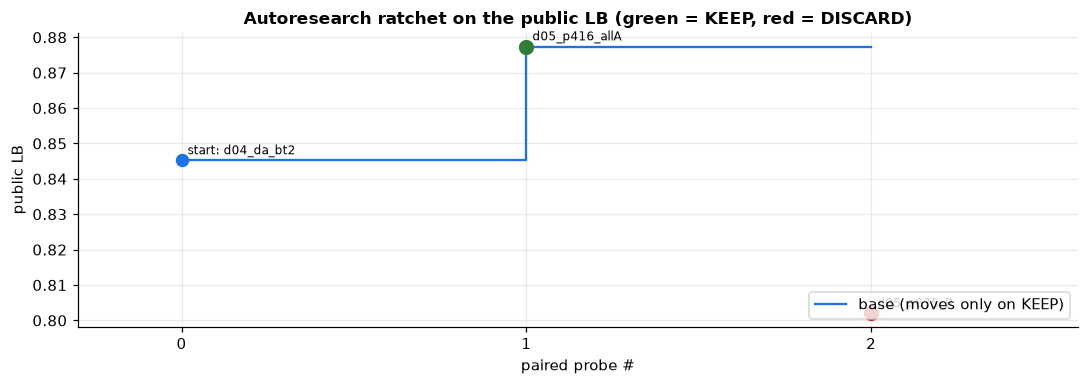

In [16]:
rt = pd.read_csv(find('results.tsv'), sep='	'); show(rt[['date_utc', 'hypothesis', 'candidate', 'changed_rows', 'actual_lb', 'implied_q', 'decision']])
done = rt[pd.to_numeric(rt.actual_lb, errors='coerce').notna()].copy(); done['lb'] = done.actual_lb.astype(float)
if len(done):
    fig, ax = plt.subplots(figsize=(10, 3.6)); base_lb = [0.84521]; ax.scatter(0, 0.84521, s=60, color=COL['blue'], zorder=3); ax.annotate('start: d04_da_bt2', (0, 0.84521), xytext=(4, 4), textcoords='offset points', fontsize=8)
    for i, r in enumerate(done.itertuples(), 1):
        keep = str(r.decision).startswith('KEEP'); ax.scatter(i, r.lb, s=80, color=COL['Aman'] if keep else COL['Rusak'], zorder=3); ax.annotate(r.candidate, (i, r.lb), xytext=(4, 4), textcoords='offset points', fontsize=8)
        base_lb.append(r.lb if keep else base_lb[-1])
    ax.step(range(len(base_lb)), base_lb, where='post', color=COL['blue'], label='base (moves only on KEEP)'); ax.set_xticks(range(len(base_lb))); ax.set_xlim(-0.3, len(base_lb) - 0.4)
    ax.set_title('Autoresearch ratchet on the public LB (green = KEEP, red = DISCARD)'); ax.set_xlabel('paired probe #'); ax.set_ylabel('public LB'); ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

## 12b. Iteration log
Experiments are ranked by strength of evidence: paired LB reads first, then single LB scores, the test-domain gate, and honest group-OOF last.

| step | hypothesis | evidence | decision |
|---|---|---|---|
| kNN/LR on DINOv2+CLIP | baseline | LB 0.786 / 0.768 | superseded |
| SSCD twin lock + DA heads | test copies carry labels | LB **0.84521** (+0.059) | kept |
| no lock (paired) | twin labels hurt? | LB 0.83004 | lock right ~55% on contested rows |
| 416 → Aman (paired) | synthetic test source is intact boxes | LB **0.87739** (+0.032) | kept |
| no-copy 675 → Rusak (paired) | copy structure | LB 0.80201 (−0.043) | refuted: 675 is Aman |
| DINOv3-H+ fine-tune | breaks the augmentation shortcut | gate G1n 0.923 → 0.476 | final model F1 |
| `augeq` always-corrupt | removes the shortcut entirely | gate 0.515 | closed |
| VLM towers, cleanlab relabel, Lainnya prior-match, iterative PL | — | below the +0.005 bar or LB loss | closed |

In [17]:
stage('log')
EVID = {'LB paired': 0, 'OOF honest + LB': 0, 'LB probe (pending 10-05)': 1, 'LB single': 2, 'test-domain held-out': 3, 'test-domain': 3, 'OOF honest': 4, 'OOF vs LB': 4,
        'OOF honest (cleaned)': 5, 'OOF leaky': 6, 'audit': 7, 'count': 7, 'design': 8}
ex = pd.read_csv(find('experiments.csv')).fillna(''); ex['_e'] = ex.evidence.map(EVID).fillna(9)
show(ex.sort_values('_e')[['category', 'experiment', 'metric_oof_orig', 'lb_public', 'evidence', 'decision']].reset_index(drop=True), 80)

== §12 log | elapsed 0.9 min | planned remaining 2 min


            category                                                                                                                    experiment              metric_oof_orig lb_public                  evidence                                                decision
0         leakage+DA                                         SSCD twin lock (0.55 purity>=0.9 clean_other) + domain-adapted MLP heads (d04_da_bt2)                      0.9318*   0.84521                 LB paired                                     ADOPTED (team best)
1       architecture                                                    Plain h2 heads (MLP cat6+PE-G & cat11) at 27.4% Rusak (d05_h2_nolock_s337)                       0.8967   0.83004                 LB paired                                                BASELINE
2           cleaning                                                                          Confident-learning relabel 700 rows (r1003_clean_v1)                       0.7856   0.76761           

## 13. Final submissions
Two picks for private scoring. They are ranked by expected public LB and by evidence strength, and are updated as the remaining daily LB reads arrive.

In [18]:
stage('final')
FINAL = [('d06_cur_A', 0.883, 'extends a paired LB finding (416/675 test rows are Aman, q ≈ 0) to the 25 remaining curated-source Rusak calls; low variance'),
         ('d05_p416_allA', 0.87739, 'best confirmed public LB; same pipeline minus 25 rows; the safe anchor')]
fin = OUT / 'final'; fin.mkdir(exist_ok=True); rows = []
for name, exp, why in FINAL:
    sub = to_sub(SUBS[name]); f = fin / f'submission_{name}.csv'; sub.to_csv(f, index=False)
    rows.append((name, exp, sub.label.value_counts(normalize=True).round(3).to_dict(), hashlib.md5(f.read_bytes()).hexdigest()[:10], why))
show(pd.DataFrame(rows, columns=['submission', 'expected public LB', 'class mix', 'md5', 'reason']))
for n, l in SUBS.items(): to_sub(l).to_csv(OUT / f'submission_{n}.csv', index=False)
print('all submissions written to', rel(OUT), '| notebook finished in', f'{(time.time() - T0) / 60:.1f} min')

== §13 final | elapsed 0.9 min | planned remaining 1 min


      submission  expected public LB                                          class mix         md5                                                                                                                        reason
0      d06_cur_A             0.88300  {'Aman': 0.761, 'Rusak': 0.221, 'Lainnya': 0.018}  2439030436  extends a paired LB finding (416/675 test rows are Aman, q ≈ 0) to the 25 remaining curated-source Rusak calls; low variance
1  d05_p416_allA             0.87739   {'Aman': 0.752, 'Rusak': 0.23, 'Lainnya': 0.018}  7b4d91044c                                                        best confirmed public LB; same pipeline minus 25 rows; the safe anchor


all submissions written to notebook/output | notebook finished in 0.9 min
